# Лабораторная работа №1. Линейная регрессия

Богданов Михаил, М8О-314БВ-24.

Задача — предсказать `RiskScore`. Цель на Kaggle — MSE ниже 19. Признаки из генератора использовать нельзя.

Ноутбук запускается из папки `lab1/`, данные лежат в `data/`.

In [2]:
import sys

sys.path.append("src")

import numpy as np
import pandas as pd
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score,
    mean_absolute_percentage_error,
)

import clean
import scalers
import linear
import metrics
import cv

train = pd.read_csv("data/train.csv")
test = pd.read_csv("data/test.csv")
print("Train:", train.shape, " Test:", test.shape)

Train: (11017, 35)  Test: (5000, 35)


## 1. Данные и EDA

Убираем дубликаты и строки с пропущенным или техническим `RiskScore`. Для учебной регрессии заполняем пропуски в признаках, а графики строим до заполнения.

In [3]:
train.info()
display(train.describe().T)
display(train["RiskScore"].describe())

print("Пропуски в train:", int(train.isnull().sum().sum()),
      " Дубликаты:", int(train.duplicated().sum()),
      " Пропуски в test:", int(test.isnull().sum().sum()))
print("Категориальные:", train.select_dtypes(include=["object", "string"]).columns.tolist())

<class 'pandas.DataFrame'>
RangeIndex: 11017 entries, 0 to 11016
Data columns (total 35 columns):
 #   Column                      Non-Null Count  Dtype
---  ------                      --------------  -----
 0   ApplicationDate             10487 non-null  str
 1   Age                         10487 non-null  float64
 2   AnnualIncome                10487 non-null  float64
 3   CreditScore                 9986 non-null   float64
 4   LoanAmount                  9986 non-null   float64
 5   LoanDuration                10487 non-null  float64
 6   MaritalStatus               10487 non-null  str
 7   NumberOfDependents          10487 non-null  float64
 8   HomeOwnershipStatus         10487 non-null  str
 9   MonthlyDebtPayments         9986 non-null   float64
 10  CreditCardUtilizationRate   10487 non-null  float64
 11  NumberOfOpenCreditLines     10487 non-null  float64
 12  NumberOfCreditInquiries     10487 non-null  float64
 13  DebtToIncomeRatio           10487 non-null  float64
 14  B

,count,mean,std,min,25%,50%,75%,max
Age,10487.0,39.850386,1.161413e+01,1.800000e+01,32.000000,40.000000,48.000000,8.000000e+01
AnnualIncome,10487.0,131587.872127,1.157919e+05,1.500000e+04,20959.500000,89015.000000,257025.000000,7.485080e+05
CreditScore,9986.0,678.082716,1.751925e+02,3.000000e+02,550.000000,722.500000,850.000000,8.500000e+02
LoanAmount,9986.0,29874.218306,2.770551e+04,1.063000e+03,12658.000000,21828.500000,37158.000000,4.189970e+05
LoanDuration,10487.0,53.439878,2.449356e+01,1.200000e+01,36.000000,48.000000,60.000000,1.200000e+02
NumberOfDependents,10487.0,1.568323,1.418684e+00,0.000000e+00,0.000000,1.000000,3.000000,6.000000e+00
MonthlyDebtPayments,9986.0,546.458642,5.019819e+02,1.300000e+01,233.250000,398.000000,685.000000,1.087900e+04
CreditCardUtilizationRate,10487.0,0.284397,1.592405e-01,3.673558e-03,0.158929,0.262229,0.391683,9.146347e-01
NumberOfOpenCreditLines,10487.0,3.033565,1.740186e+00,0.000000e+00,2.000000,3.000000,4.000000,1.200000e+01
NumberOfCreditInquiries,10487.0,0.979498,9.909274e-01,0.000000e+00,0.000000,1.000000,2.000000,6.000000e+00


count    1.048700e+04
mean    -2.569878e+04
std      1.431675e+06
min     -9.999999e+06
25%      3.256475e+01
50%      4.411876e+01
75%      6.535690e+01
max      1.000000e+07
Name: RiskScore, dtype: float64

Пропуски в train: 23059  Дубликаты: 1016  Пропуски в test: 0
Категориальные: ['ApplicationDate', 'MaritalStatus', 'HomeOwnershipStatus', 'LoanPurpose', 'EmploymentStatus', 'EducationLevel']


In [4]:
train_clean = clean.fill_missing(clean.filter_risk(clean.drop_duplicates(train)))
test_clean = clean.fill_missing(test)
print("Строк после очистки:", len(train_clean), " Test:", test_clean.shape)

Удалено дубликатов: 1016
Удалено выбросов RiskScore: 213
Пропусков осталось: 0
Пропусков осталось: 0
Строк после очистки: 9788  Test: (5000, 35)


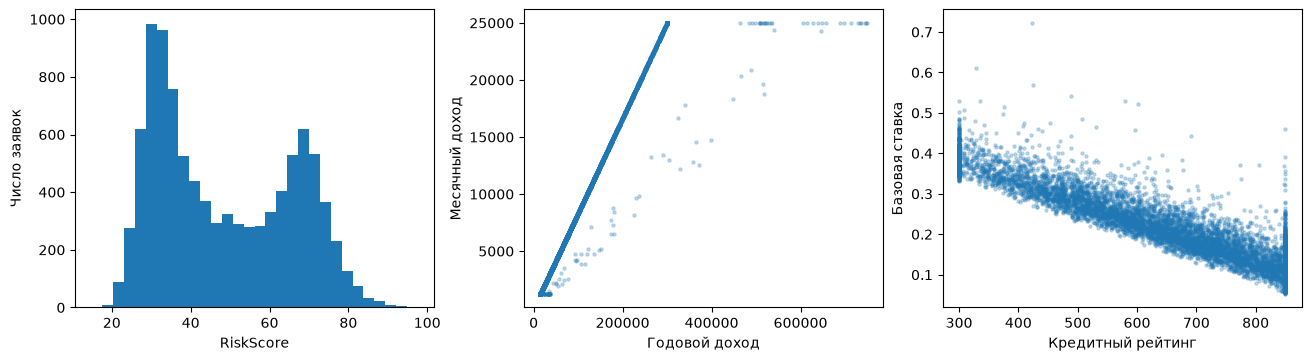

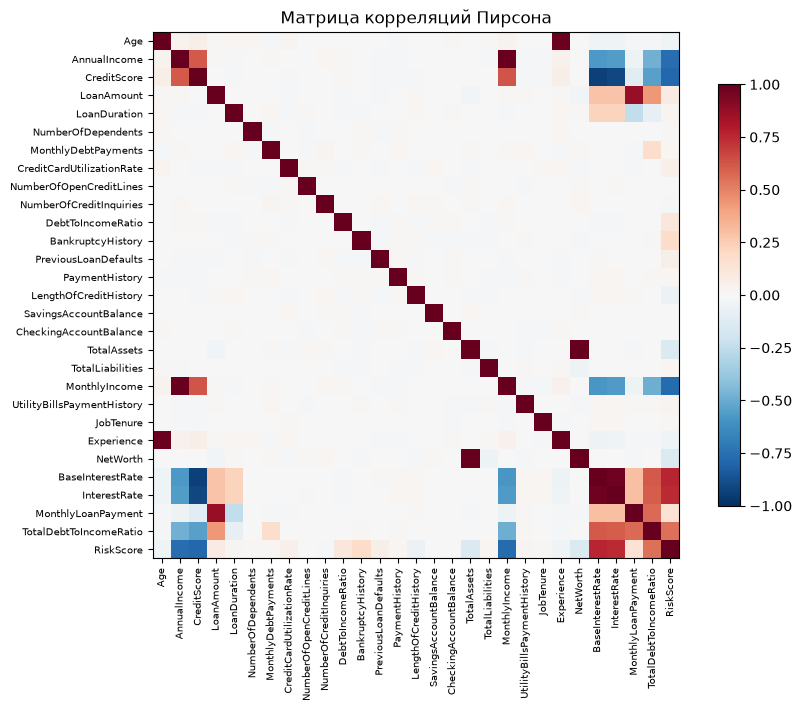

In [5]:
%matplotlib inline
import matplotlib.pyplot as plt
from validate_risk import training_rows

eda = training_rows(train)  # Без дубликатов и технических значений цели, до заполнения пропусков.
fig, (target_ax, income_ax, credit_ax) = plt.subplots(1, 3, figsize=(13, 3.5), layout="constrained")
target_ax.hist(eda["RiskScore"], bins=30)
target_ax.set(xlabel="RiskScore", ylabel="Число заявок")
income_ax.scatter(eda["AnnualIncome"], eda["MonthlyIncome"], s=5, alpha=0.25)
income_ax.set(xlabel="Годовой доход", ylabel="Месячный доход")
credit_ax.scatter(eda["CreditScore"], eda["BaseInterestRate"], s=5, alpha=0.25)
credit_ax.set(xlabel="Кредитный рейтинг", ylabel="Базовая ставка")
plt.show()

corr = eda.select_dtypes(include="number").corr()
fig, ax = plt.subplots(figsize=(9, 7), layout="constrained")
image = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ticks = np.arange(len(corr))
ax.set_xticks(ticks, corr.columns, rotation=90, fontsize=7)
ax.set_yticks(ticks, corr.index, fontsize=7)
ax.set_title("Матрица корреляций Пирсона")
fig.colorbar(image, ax=ax, shrink=0.8)
plt.show()

У `RiskScore` два пика — около 30 и 65. Месячный доход растёт вместе с годовым, но не превышает 25 000. При высоком кредитном рейтинге базовая ставка обычно ниже. С самим `RiskScore` рейтинг тоже связан отрицательно: корреляция −0.785.

## 2. Нормализация

Категории кодируем через one-hot. Результаты z-score и min-max сверяем со sklearn.

In [6]:
X, y, X_test = clean.prepare_features(train_clean, test_clean)
print("X:", X.shape, " y:", y.shape, " X_test:", X_test.shape)

X_z = scalers.ZScoreScaler().fit_transform(X)
X_mm = scalers.MinMaxScaler().fit_transform(X)

from sklearn.preprocessing import StandardScaler, MinMaxScaler
print("z-score: max |diff| со sklearn =", np.abs(X_z - StandardScaler().fit_transform(X)).max())
print("min-max: max |diff| со sklearn =", np.abs(X_mm - MinMaxScaler().fit_transform(X)).max())

X: (9788, 44)  y: (9788,)  X_test: (5000, 44)
z-score: max |diff| со sklearn = 0.0
min-max: max |diff| со sklearn = 2.220446049250313e-16


## 3. Линейная регрессия

Сравниваем аналитическое решение, GD и SGD на одном разбиении. Аналитическое решение отдельно сверяем со sklearn.

In [7]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

X_train, X_val, y_train, y_val = train_test_split(X_z, y, test_size=0.2, random_state=42)

models = {
    "Analytical": linear.MyLinearRegression(method="analytical"),
    "GD": linear.MyLinearRegression(method="gd", lr=0.1, n_iter=3000),
    "SGD": linear.MyLinearRegression(method="sgd", lr=0.01, n_iter=100, batch_size=64),
}

results = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    results[name] = {
        "model": model,
        "mse_train": metrics.mse_metric(y_train, model.predict(X_train)),
        "mse_val": metrics.mse_metric(y_val, model.predict(X_val)),
        "mae_val": metrics.mae_metric(y_val, model.predict(X_val)),
        "r2_val": metrics.r2_metric(y_val, model.predict(X_val)),
    }
    r = results[name]
    print(name, " MSE_train =", round(r["mse_train"], 3), " MSE_val =", round(r["mse_val"], 3),
          " MAE_val =", round(r["mae_val"], 3), " R2_val =", round(r["r2_val"], 3))

sk_lr = LinearRegression().fit(X_train, y_train)
print("sklearn MSE_val =", round(metrics.mse_metric(y_val, sk_lr.predict(X_val)), 3),
      " max |разница коэффициентов| =",
      round(float(np.max(np.abs(results["Analytical"]["model"].coef_ - sk_lr.coef_))), 12))

Analytical  MSE_train = 51.259  MSE_val = 55.769  MAE_val = 5.963  R2_val = 0.817
GD  MSE_train = 51.259  MSE_val = 55.767  MAE_val = 5.962  R2_val = 0.817
SGD  MSE_train = 51.779  MSE_val = 56.501  MAE_val = 5.983  R2_val = 0.814
sklearn MSE_val = 55.769  max |разница коэффициентов| = 2e-12


## 4. Метрики: MSE, MAE, R², MAPE

Считаем метрики своими функциями и через sklearn на одних прогнозах. MAPE выводим в процентах.

In [8]:
y_pred = results["Analytical"]["model"].predict(X_val)

print("MSE:  свой =", round(metrics.mse_metric(y_val, y_pred), 6),
      " sklearn =", round(mean_squared_error(y_val, y_pred), 6))
print("MAE:  свой =", round(metrics.mae_metric(y_val, y_pred), 6),
      " sklearn =", round(mean_absolute_error(y_val, y_pred), 6))
print("R2:   свой =", round(metrics.r2_metric(y_val, y_pred), 6),
      " sklearn =", round(r2_score(y_val, y_pred), 6))
print("MAPE: свой =", round(metrics.mape_metric(y_val, y_pred), 6),
      " sklearn =", round(mean_absolute_percentage_error(y_val, y_pred) * 100, 6))

MSE:  свой = 55.768971  sklearn = 55.768971
MAE:  свой = 5.962569  sklearn = 5.962569
R2:   свой = 0.81657  sklearn = 0.81657
MAPE: свой = 13.957041  sklearn = 13.957041


## 5. K-fold и leave-one-out

Для k-fold берём 5 частей. Обычный LOO считаем на 300 строках, а на всей выборке — по формуле без повторного обучения.

In [9]:
my_cv = cv.kfold_mse(lambda: linear.MyLinearRegression(method="analytical"), X_z, y, 5)
print("Свой k-fold (5):", my_cv.round(3), " mean =", round(my_cv.mean(), 3), " std =", round(my_cv.std(), 3))

from sklearn.model_selection import cross_val_score
sk_cv = -cross_val_score(LinearRegression(), X_z, y, cv=5, scoring="neg_mean_squared_error")
print("Sklearn k-fold: ", sk_cv.round(3), " mean =", round(sk_cv.mean(), 3))

loo_small = cv.loo_mse(lambda: linear.MyLinearRegression(method="analytical"), X_z, y, limit=300)
print("Свой LOO на 300 объектах: mean =", round(loo_small.mean(), 3), " std =", round(loo_small.std(), 3))
print("LOO на всех", len(X_z), "объектах (hat-матрица):", round(cv.loo_mse_fast(X_z, y), 3))

Свой k-fold (5): [55.769 53.482 48.774 53.732 52.349]  mean = 52.821  std = 2.305
Sklearn k-fold:  [50.594 53.468 54.368 54.065 51.038]  mean = 52.706
Свой LOO на 300 объектах: mean = 56.578  std = 85.722
LOO на всех 9788 объектах (hat-матрица): 52.78


## 6. Регуляризация (бонус)

Проверяем L1, L2, Elastic Net и Lp. Для каждого варианта выбираем параметры по MSE на валидации.

In [10]:
reg_results = {}
for reg in ["l2", "l1", "elastic", "lp"]:
    best = (None, None, float("inf"))
    for alpha in [0.01, 0.1, 1.0, 10.0]:
        for p in ([1.5, 2, 3] if reg == "lp" else [None]):
            kwargs = {} if p is None else {"p": p}
            m = linear.MyRegularizedRegression(reg_type=reg, alpha=alpha, **kwargs)
            m.fit(X_train, y_train)
            mse = metrics.mse_metric(y_val, m.predict(X_val))
            if mse < best[2]:
                best = (alpha, p, mse)
    reg_results[reg] = best
    print(reg, ": alpha =", best[0], " p =", best[1], " MSE_val =", round(best[2], 3))

from sklearn.linear_model import Ridge, Lasso, ElasticNet

for name, cls, params in [
    ("Ridge", Ridge, {"alpha": 1.0}),
    ("Lasso", Lasso, {"alpha": 0.1, "max_iter": 5000}),
    ("ElasticNet", ElasticNet, {"alpha": 0.1, "l1_ratio": 0.5, "max_iter": 5000}),
]:
    m = cls(**params).fit(X_train, y_train)
    print(name, ": MSE =", round(metrics.mse_metric(y_val, m.predict(X_val)), 3),
          " R2 =", round(metrics.r2_metric(y_val, m.predict(X_val)), 3))

l2 : alpha = 10.0  p = None  MSE_val = 55.742
l1 : alpha = 0.1  p = None  MSE_val = 55.535
elastic : alpha = 0.01  p = None  MSE_val = 55.682
lp : alpha = 0.01  p = 1.5  MSE_val = 55.697
Ridge : MSE = 55.766  R2 = 0.817
Lasso : MSE = 55.567  R2 = 0.817
ElasticNet : MSE = 55.91  R2 = 0.816


## 7. Модель для Kaggle

Идея двух веток и выбор исходных полей опираются на [решение liptonMartin](https://github.com/liptonMartin/mai_labs_machine_learning) (`lab_1/01_train_sklearn.ipynb`). Числовые границы не заданы вручную. В каждом фолде модель заново подбирает их по обучающей части и применяет к проверочной без изменений.

**Как находим пороги.** Для шести числовых полей начинаем с квантилей обучающей выборки (20, 40, 60 и 80%). Подгоняем две регрессии, ограничиваем влияние больших остатков и для каждого поля смотрим на ту часть целевого балла, которую остальные признаки не объяснили. Среди наблюдаемых значений поля ищем разрез с наибольшим снижением суммы квадратов ошибок по сравнению с одним средним на весь интервал. Оставляем не меньше 20 строк с каждой стороны; добавляем до пяти разрезов на поле, пока выигрыш превышает штраф за дополнительный разрез. Уточняем границы между соседними интервалами. Всю процедуру повторяем пять раз.

**Как прогнозируем.** Шесть признаков считают пройденные пороги; ещё три — флаги банкротства, прошлого дефолта и статуса занятости, отличного от `Employed`. Для обучения веток делим строки по медиане `RiskScore`, затем чередуем подгонку двух линейных регрессий и отнесение каждой строки к ветке с меньшей ошибкой. Отдельная регрессия по 12 признакам заявки даёт вес `p`, который ограничиваем интервалом от 0 до 1. Итог — `(1 − p) · нижний прогноз + p · верхний прогноз`.

При `use_branches=False` подготовка девяти признаков та же (включая подбор границ с двумя вспомогательными ветками), но итоговый прогноз даёт одна регрессия, без смешивания. Так сравниваем именно способ прогноза.

In [11]:
from pathlib import Path
from threadpoolctl import threadpool_limits

from src.branch_mixture import BranchMixtureRegression, CompleteRowsOnly
from validate_risk import training_rows, cross_validate


def branch_model(use_branches=True):
    return CompleteRowsOnly(BranchMixtureRegression(use_branches=use_branches))


raw = training_rows(train)
with threadpool_limits(limits=2):
    two = cross_validate(raw, model_factory=branch_model, n_splits=5, seed=314159)
    one = cross_validate(raw, model_factory=lambda: branch_model(False), n_splits=5, seed=314159)
    final_model = branch_model().fit(raw)
    final_preds = final_model.predict(test)

print()
print("5-fold OOF  полные строки:  две ветки =", round(two["oof"]["complete_mse"], 4),
      " без веток =", round(one["oof"]["complete_mse"], 4))
print("5-fold OOF  все строки:     две ветки =", round(two["oof"]["mse"], 4),
      " без веток =", round(one["oof"]["mse"], 4))

assert final_preds.shape == (len(test),) and np.isfinite(final_preds).all()
submission_candidate = pd.DataFrame({"ID": test["ID"], "RiskScore": final_preds})
output_path = Path("submission_branch_learned.csv")
if output_path.exists():
    previous = pd.read_csv(output_path)
    assert previous.ID.equals(submission_candidate.ID)
    np.testing.assert_allclose(previous.RiskScore, final_preds, rtol=1e-9, atol=1e-9)
    print("Существующий submission_branch_learned.csv совпадает с прогнозом; не перезаписываем.")
else:
    with output_path.open("x", encoding="utf-8", newline="") as output:
        submission_candidate.to_csv(output, index=False)
print(output_path, submission_candidate.shape, "признаков на ветку:", final_model.n_features_)
print("Границы на полном обучающем наборе:")
for name, cuts in final_model.inner.cuts_.items():
    print(name, np.round(cuts, 4).tolist())
submission_candidate.head()

{"rows": 1958, "mse": 24.178918396321567, "mae": 3.3027914031720202, "r2": 0.9202952553341146, "complete_rows": 1871, "complete_mse": 18.578054567618867, "incomplete_rows": 87, "incomplete_mse": 144.62967958600834, "fold": 1, "features": 9}


{"rows": 1958, "mse": 24.54631271361912, "mae": 3.3874203154074496, "r2": 0.9158628425651604, "complete_rows": 1866, "complete_mse": 18.533016166444657, "incomplete_rows": 92, "incomplete_mse": 146.51165355087514, "fold": 2, "features": 9}


{"rows": 1958, "mse": 23.734407177647252, "mae": 3.3439433053709298, "r2": 0.9207045395606406, "complete_rows": 1872, "complete_mse": 17.927062775002263, "incomplete_rows": 86, "incomplete_mse": 150.14543882591965, "fold": 3, "features": 9}


{"rows": 1957, "mse": 23.04073271212182, "mae": 3.293179130995568, "r2": 0.919503138414804, "complete_rows": 1860, "complete_mse": 18.614141754521583, "incomplete_rows": 97, "incomplete_mse": 107.92175519806456, "fold": 4, "features": 9}


{"rows": 1957, "mse": 24.65540384108543, "mae": 3.300726139675398, "r2": 0.9189226616037797, "complete_rows": 1863, "complete_mse": 18.577442841891166, "incomplete_rows": 94, "incomplete_mse": 145.11541811235048, "fold": 5, "features": 9}


{"rows": 1958, "mse": 39.794605288547, "mae": 4.446341886265703, "r2": 0.868818827971814, "complete_rows": 1871, "complete_mse": 31.16655841170447, "incomplete_rows": 87, "incomplete_mse": 225.34719961696507, "fold": 1, "features": 9}


... (2 outputs left out)

{"rows": 1957, "mse": 38.34776244708212, "mae": 4.428636689040796, "r2": 0.8660253315563733, "complete_rows": 1860, "complete_mse": 31.898431850699225, "incomplete_rows": 97, "incomplete_mse": 162.01533883133152, "fold": 4, "features": 9}


{"rows": 1957, "mse": 41.72415802408494, "mae": 4.543048730721185, "r2": 0.8627934183832384, "complete_rows": 1863, "complete_mse": 32.12795367743969, "incomplete_rows": 94, "incomplete_mse": 231.91276119217122, "fold": 5, "features": 9}



5-fold OOF  полные строки:  две ветки = 18.4455  без веток = 31.4859
5-fold OOF  все строки:     две ветки = 24.0312  без веток = 39.6589
submission_branch_learned.csv (5000, 2) признаков на ветку: 9
Границы на полном обучающем наборе:
CreditScore [600.0, 650.0, 700.0, 750.0]
DebtToIncomeRatio [0.2, 0.2999, 0.3998, 0.4997]
CreditCardUtilizationRate [0.1988, 0.4104, 0.5965]
LengthOfCreditHistory [3.0, 7.0, 10.0]
AnnualIncome [30044.0, 49916.0, 78593.0, 119700.0]
NetWorth [50072.0, 100251.0, 249114.0, 516186.0]


,ID,RiskScore
0,0,32.913445
1,1,53.428961
2,2,30.223800
3,3,35.137258
4,4,33.209341


### Локальная проверка: 5 фолдов, seed = 314159

| Прогноз на девяти признаках с обучаемыми границами | MSE на всех 9 788 строках | MSE на 9 332 полных строках |
|---|---:|---:|
| Одна регрессия | 39.6589 | 31.4859 |
| Две ветки | 24.0312 | 18.4455 |

Модель обучается на полных строках обучающей части фолда, но оценивается на всех строках проверочной части. На 456 строках с пропусками MSE смеси — 138.3413. Таблица `test.csv` полная; новый прогноз сохранён в `submission_branch_learned.csv`.

## Вывод

Замена фиксированных границ обучаемыми увеличила локальную MSE на полных строках с 18.3210 до 18.4455. На исходном разбиении все пять фолдов ниже 19. При seed = 42 итог на полных строках — 18.4543, хотя один фолд дал 19.3316. На всей выборке порог 19 не достигнут. Это кросс-валидация, не результат Kaggle.

Обе ветки по отдельности — линейные регрессии. Смесь с зависящим от заявки весом — не одна линейная регрессия.